# Praktikum Data Mining
## Evaluasi Model Klasifikasi: Confusion Matrix, Accuracy, Precision, Recall dan F1-Score

Kode mengikuti Bagian 4.1–4.8 modul praktikum (UNP 2026).
Nama Kelompok 
Aulia Safitri (24343002)
Harits Tsaqif (24343009)
Famos Kinlyvent Sarumaha (24343034)


## Tugas 1 — Hitung Manual (TP=24, TN=156, FP=12, FN=8)

In [1]:
TP, TN, FP, FN = 24, 156, 12, 8
acc = (TP + TN) / (TP + TN + FP + FN)
prec = TP / (TP + FP)
rec = TP / (TP + FN)
f1_m = 2 * prec * rec / (prec + rec)
print(f'Accuracy  = {acc:.4f}')
print(f'Precision = {prec:.4f}')
print(f'Recall    = {rec:.4f}')
print(f'F1-Score  = {f1_m:.4f}')

Accuracy  = 0.9000
Precision = 0.6667
Recall    = 0.7500
F1-Score  = 0.7059


## Tugas 2 — Verifikasi Python
### 4.1 Menyiapkan Dataset Sintetis

In [2]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n = 500

amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

score = -4.5 + 0.45*(amount > 300) + 1.1*new_device + 1.5*foreign_ip + 0.7*(hour < 5)
prob = 1/(1+np.exp(-score))
isFraud = rng.binomial(1, prob)

df = pd.DataFrame({'amount': amount.round(2), 'hour': hour,
                   'new_device': new_device, 'foreign_ip': foreign_ip,
                   'isFraud': isFraud})
print(df.head())
print('Distribusi kelas:')
print(df['isFraud'].value_counts())

# (opsional) simpan dataset
# df.to_csv('dataset.csv', index=False)

   amount  hour  new_device  foreign_ip  isFraud
0  201.28     9           0           0        0
1   52.46     8           0           0        0
2  314.33    17           1           0        0
3  380.15     3           0           0        0
4   21.09     5           1           0        0
Distribusi kelas:
isFraud
0    484
1     16
Name: count, dtype: int64


### 4.2 Membagi Data dan Melatih Model

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns='isFraud')
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print('Data uji:', len(y_test))

Data uji: 150


### 4.3 Confusion Matrix

In [4]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tn, fp, fn, tp = cm.ravel()
print('Confusion matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

Confusion matrix:
 [[113  32]
 [  3   2]]
TP=2, TN=113, FP=32, FN=3


### 4.4 Perhitungan Manual dan Verifikasi scikit-learn

In [5]:
accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0
f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
print(f'Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}')

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print(accuracy_score(y_test,y_pred), precision_score(y_test,y_pred,zero_division=0),
      recall_score(y_test,y_pred,zero_division=0), f1_score(y_test,y_pred,zero_division=0))

Accuracy=0.767; Precision=0.059; Recall=0.400; F1=0.103
0.7666666666666667 0.058823529411764705 0.4 0.10256410256410256


### 4.5 Visualisasi Confusion Matrix

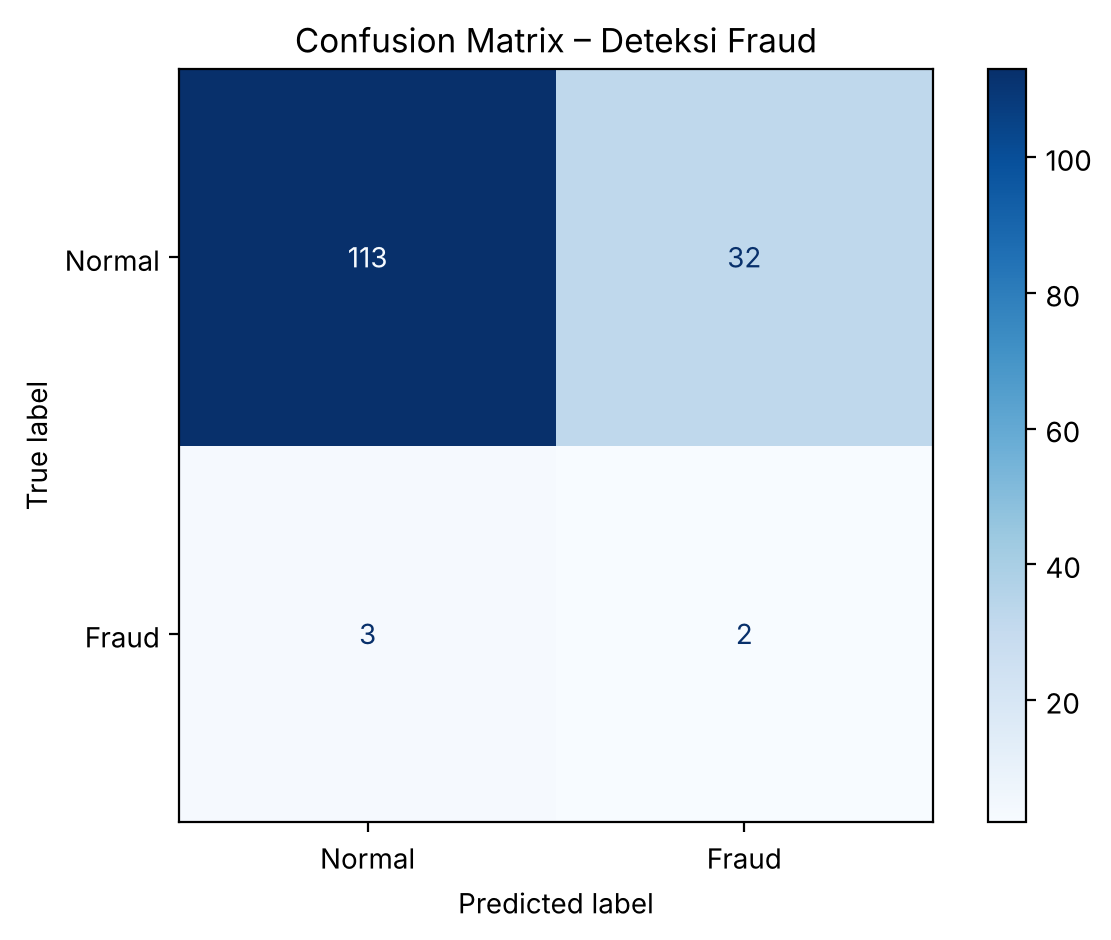

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=['Normal','Fraud']).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix – Deteksi Fraud')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

## Tugas 3 — Evaluasi Data Tidak Seimbang (Bagian 4.7)

In [7]:
baseline = np.zeros(len(y_test), dtype=int)
from sklearn.metrics import classification_report
print('Baseline accuracy:', accuracy_score(y_test, baseline))
print(classification_report(y_test, baseline, labels=[0,1], zero_division=0))
print('Decision Tree:')
print(classification_report(y_test, y_pred, labels=[0,1], zero_division=0))

Baseline accuracy: 0.9666666666666667
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       145
           1       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

Decision Tree:
              precision    recall  f1-score   support

           0       0.97      0.78      0.87       145
           1       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



## Tugas 4 — Eksperimen Threshold (Bagian 4.8)

In [8]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    print(threshold, 'precision=', round(precision_score(y_test,pred,zero_division=0),3),
          'recall=', round(recall_score(y_test,pred,zero_division=0),3))

0.2 precision= 0.059 recall= 0.4
0.4 precision= 0.059 recall= 0.4
0.5 precision= 0.059 recall= 0.4
0.7 precision= 0.056 recall= 0.2
